# Praktikum LP02: Harris Corner Detector
**Computer Vision Application**

Notebook ini menggabungkan seluruh implementasi dan analisis dari tugas praktikum LP02:
* **Soal 1 (Dicky Azkia)**: Perhitungan Sum of Squared Differences (SSD) / Corner Score $E(u,v)$ dan Gradien Citra ($I_x, I_y, I_x^2, I_y^2, I_x I_y$).
* **Soal 2 (Raka Santang & Naufal Hugo)**: Struktur Matriks Harris (Second-Moment Matrix $M$), Fungsi Respon Sudut Harris $R$, Thresholding, dan Non-Maximum Suppression (NMS).
* **Soal 3 (Fergiant)**: Visualisasi Sudut pada Citra, Visualisasi 4-Panel Komparatif, dan Integrasi Seluruh Pipeline.


In [1]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

print("OpenCV Version :", cv2.__version__)
print("NumPy Version  :", np.__version__)


OpenCV Version : 5.0.0
NumPy Version  : 2.5.4


## 1. Persiapan Citra Input
Citra `building.png` dimuat dalam format warna BGR dan dikonversi ke Grayscale.
Untuk komputasi diferensiasi dan perkalian gradien dengan presisi tinggi, citra grayscale dikonversi ke `float32`.


Resolusi Citra BGR   : (744, 992, 3)
Resolusi Citra Gray  : (744, 992)
Rentang Nilai Piksel : [0, 255]


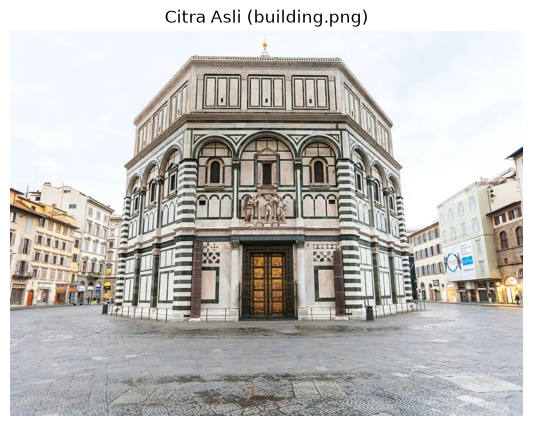

In [2]:
image_path = "building.png"
img_bgr = cv2.imread(image_path)
if img_bgr is None:
    raise FileNotFoundError(f"Citra '{image_path}' tidak ditemukan!")

img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_float = img_gray.astype(np.float32)

print(f"Resolusi Citra BGR   : {img_bgr.shape}")
print(f"Resolusi Citra Gray  : {img_gray.shape}")
print(f"Rentang Nilai Piksel : [{img_gray.min()}, {img_gray.max()}]")

plt.figure(figsize=(8, 5))
plt.title("Citra Asli (building.png)")
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


---
## 2. Soal 1: SSD Corner Score & Gradien Citra

### Teori:
1. **Sum of Squared Differences (SSD)** mengukur perubahan intensitas ketika sebuah window lokal digeser sebesar $(u, v)$:
   $$E(u, v) = \sum_{(x, y) \in W} [I(x+u, y+v) - I(x, y)]^2$$
   * Pada area datar (*flat*), $E(u, v) \approx 0$ ke segala arah pergeseran.
   * Pada garis tepi (*edge*), $E(u, v)$ bernilai kecil saat digeser sejajar garis tepi dan bernilai besar jika tegak lurus.
   * Pada sudut (*corner*), $E(u, v)$ bernilai besar untuk semua arah pergeseran.

2. **Gradien Citra ($I_x, I_y$)** dihitung menggunakan operator Sobel 3x3:
   $$I_x = \frac{\partial I}{\partial x}, \quad I_y = \frac{\partial I}{\partial y}$$
   Serta produk kuadrat dan silangnya: $I_{xx} = I_x^2$, $I_{yy} = I_y^2$, dan $I_{xy} = I_x I_y$.


In [3]:
def corner_score(image, u=5, v=5, window_size=(5, 5)):
    """
    Menghitung Sum of Squared Differences (SSD) untuk deteksi sudut.
    Menggunakan zero-padding untuk menangani nilai window di luar batas citra.
    """
    H, W = image.shape
    shifted_image = np.zeros_like(image, dtype=np.float32)

    start_y, end_y = max(0, v), min(H, H + v)
    start_x, end_x = max(0, u), min(W, W + u)
    src_start_y, src_end_y = max(0, -v), min(H, H - v)
    src_start_x, src_end_x = max(0, -u), min(W, W - u)

    shifted_image[start_y:end_y, start_x:end_x] = image[
        src_start_y:src_end_y, src_start_x:src_end_x
    ]

    # Menghitung perbedaan kuadrat
    squared_diff = (shifted_image - image.astype(np.float32)) ** 2

    # Mengaplikasikan window dengan box filter
    output = cv2.boxFilter(
        squared_diff, -1, window_size, normalize=False, borderType=cv2.BORDER_CONSTANT
    )

    return output


def compute_image_gradients(image):
    """
    Menghitung gradien citra Ix, Iy dan perkaliannya (Ix^2, Iy^2, IxIy)
    menggunakan operator Sobel untuk persiapan matriks Harris.
    """
    Ix = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

    Ixx = Ix ** 2
    Iyy = Iy ** 2
    Ixy = Ix * Iy

    return Ix, Iy, Ixx, Iyy, Ixy


Shape score SSD : (744, 992)
Shape Ix        : (744, 992)
Min / Max Ix    : (np.float64(-914.0), np.float64(931.0))
Min / Max Iy    : (np.float64(-924.0), np.float64(889.0))


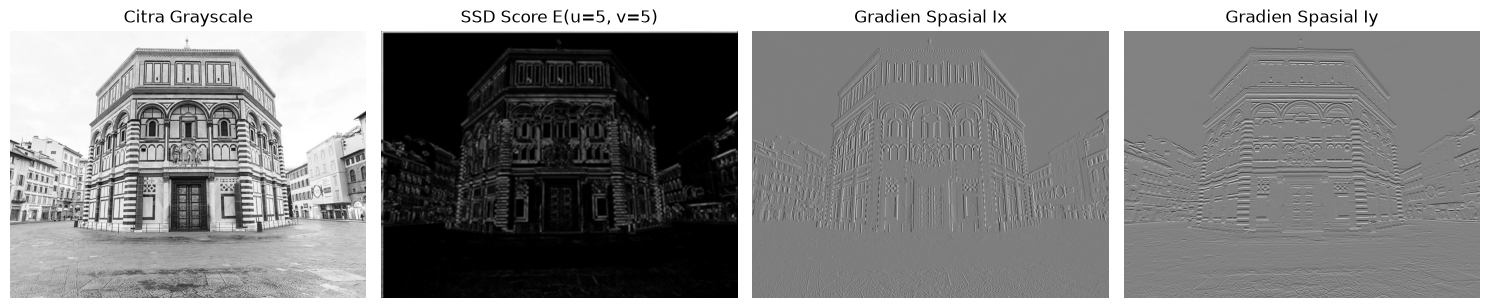

In [4]:
# Hitung SSD Score dan Gradien
score_ssd = corner_score(img_gray, u=5, v=5, window_size=(5, 5))
Ix, Iy, Ixx, Iyy, Ixy = compute_image_gradients(img_float)

print("Shape score SSD :", score_ssd.shape)
print("Shape Ix        :", Ix.shape)
print("Min / Max Ix    :", (Ix.min(), Ix.max()))
print("Min / Max Iy    :", (Iy.min(), Iy.max()))

# Visualisasi Hasil Soal 1
plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.title("Citra Grayscale")
plt.imshow(img_gray, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("SSD Score E(u=5, v=5)")
plt.imshow(score_ssd, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("Gradien Spasial Ix")
plt.imshow(Ix, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.title("Gradien Spasial Iy")
plt.imshow(Iy, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()


---
## 3. Soal 2: Struktur Matriks Harris, Respon $R$, dan NMS

### Teori:
1. **Struktur Matriks Harris (Second-Moment Matrix $M$)**:
   Aproksimasi orde pertama Taylor terhadap $E(u, v)$ menghasilkan bentuk kuadratik $E(u, v) \approx [u, v] M [u, v]^T$, dengan:
   $$M = \sum_{(x, y) \in W} w(x, y) \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix} = \begin{bmatrix} A & C \\ C & B \end{bmatrix}$$
   di mana $w(x, y)$ adalah bobot window (Gaussian atau Box filter).

2. **Corner Response Measure ($R$)**:
   Untuk menghindari komputasi *eigenvalue* eksplisit $\lambda_1, \lambda_2$, digunakan formulasi determinan dan *trace*:
   $$R = \det(M) - k \cdot (\text{trace}(M))^2$$
   $$\det(M) = A B - C^2, \quad \text{trace}(M) = A + B$$
   dengan parameter empiris $k \approx 0.04 - 0.06$.

3. **Thresholding & Non-Maximum Suppression (NMS)**:
   * Menentukan ambang batas: $T = \text{threshold\_ratio} \times \max(R)$.
   * NMS menggunakan operasi morfologi dilasi `cv2.dilate` untuk mengeliminasi kandidat yang bukan maksimum lokal dalam radius window tertentu ($3\times 3$ atau $5\times 5$).


In [5]:
def compute_structure_tensor(
    Ixx, Iyy, Ixy, window_size=(5, 5), use_gaussian=True, sigma=1.0
):
    """
    Menghitung Struktur Matriks Harris (M) per piksel.

    Input:
        Ixx, Iyy, Ixy : produk gradien (hasil dari Soal 1)
        window_size   : ukuran window (tuple), contoh (5,5)
        use_gaussian  : True = Gaussian window, False = Box filter
        sigma         : sigma untuk Gaussian (hanya dipakai jika use_gaussian=True)

    Output:
        A, B, C       : hasil windowing dari Ixx, Iyy, Ixy
                        sehingga M = [[A, C], [C, B]] di setiap piksel
    """
    if use_gaussian:
        # Pastikan kernel size ganjil
        ksize = window_size[0] if window_size[0] % 2 == 1 else window_size[0] + 1
        A = cv2.GaussianBlur(Ixx, (ksize, ksize), sigma)
        B = cv2.GaussianBlur(Iyy, (ksize, ksize), sigma)
        C = cv2.GaussianBlur(Ixy, (ksize, ksize), sigma)
    else:
        # Box filter (sum dalam window, tanpa normalize)
        A = cv2.boxFilter(Ixx, -1, window_size, normalize=False)
        B = cv2.boxFilter(Iyy, -1, window_size, normalize=False)
        C = cv2.boxFilter(Ixy, -1, window_size, normalize=False)

    return A, B, C


def harris_detector(image, window_size=(5, 5), k=0.04, use_gaussian=True, sigma=1.0):
    """
    Menghitung skor Harris R = det(M) - k * trace(M)^2 untuk semua piksel.
    Output: response (HxW) dan komponen tensor (A, B, C).
    """
    if image.dtype != np.float32 and image.dtype != np.float64:
        image = image.astype(np.float32)

    # Gradien dari Soal 1
    _, _, Ixx, Iyy, Ixy = compute_image_gradients(image)

    # Struktur tensor M
    A, B, C = compute_structure_tensor(Ixx, Iyy, Ixy, window_size, use_gaussian, sigma)

    # Corner response R
    det_M = A * B - C * C
    trace_M = A + B
    response = det_M - k * (trace_M ** 2)

    return response, A, B, C


def extract_harris_corners(response, threshold_ratio=0.01, nms_size=3):
    """
    Thresholding dan Non-Maximum Suppression (NMS) pada response R.
    Output: koordinat sudut (x, y) dan mask boolean sudut.
    """
    threshold_value = threshold_ratio * response.max()

    kernel = np.ones((nms_size, nms_size), np.uint8)
    local_max = cv2.dilate(response, kernel)

    corner_mask = (response == local_max) & (response > threshold_value)

    corners_y_x = np.argwhere(corner_mask)
    corners_x_y = np.fliplr(corners_y_x)

    return corners_x_y, corner_mask


Shape response   : (744, 992)
Max response (R) : 28153232454.03833
Min response (R) : -7988267820.544381


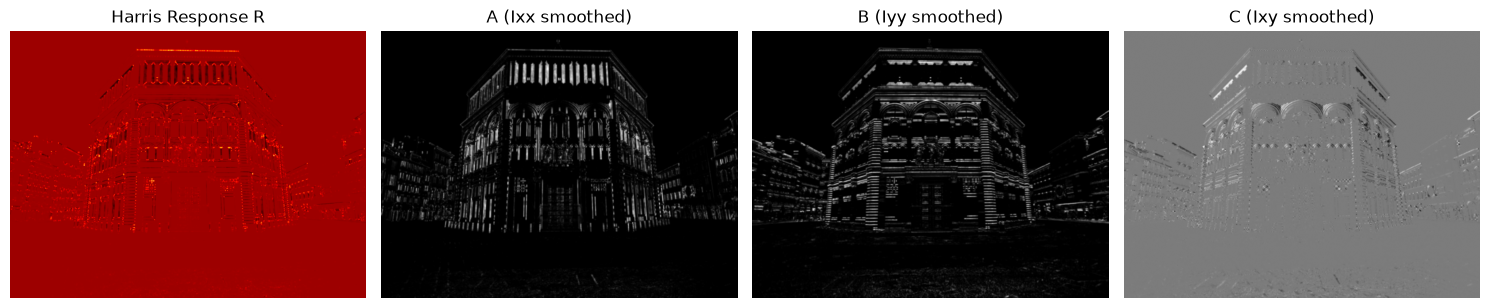

In [6]:
# Hitung Harris Response R dan Struktur Tensor M
response, A, B, C = harris_detector(
    img_gray, window_size=(5, 5), k=0.04, use_gaussian=True, sigma=1.0
)

print("Shape response   :", response.shape)
print("Max response (R) :", response.max())
print("Min response (R) :", response.min())

# Visualisasi Komponen Struktur Tensor dan Respon R
plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.title("Harris Response R")
plt.imshow(response, cmap="hot")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("A (Ixx smoothed)")
plt.imshow(A, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("B (Iyy smoothed)")
plt.imshow(B, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.title("C (Ixy smoothed)")
plt.imshow(C, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()


---
## 4. Soal 3: Visualisasi dan Integrasi Pipeline

Pada tahap ini:
1. `draw_corners`: Menggambar lingkaran penanda sudut pada citra asli (BGR).
2. `visualize`: Menampilkan 4 panel komparatif:
   * Citra Asli (Grayscale)
   * Corner Score SSD $E(u, v)$
   * Harris Response $R$
   * Sudut Terdeteksi yang dioverlay pada citra warna
3. `run_pipeline`: Menjalankan alur lengkap dari file input hingga export citra hasil ke disk (`harris_corners.png` dan `harris_result.png`).


In [7]:
def draw_corners(image_bgr, corners, radius=3, color=(0, 0, 255)):
    """
    Menggambar titik sudut (x, y) pada salinan citra BGR.
    """
    output = image_bgr.copy()
    for x, y in corners:
        cv2.circle(output, (int(x), int(y)), radius, color, -1)
    return output


def visualize_harris_pipeline(
    gray, score, response, corner_img, u=5, v=5, num_corners=None, output_path="harris_result.png"
):
    """
    Menampilkan citra asli, skor SSD E(u,v), response Harris R, dan hasil deteksi sudut.
    Menyimpan ke file dan merender di notebook.
    """
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].set_title("Citra Asli (Grayscale)")
    axes[0].imshow(gray, cmap="gray")
    axes[0].axis("off")

    axes[1].set_title(f"Corner Score E(u={u}, v={v})")
    axes[1].imshow(score, cmap="gray")
    axes[1].axis("off")

    axes[2].set_title("Harris Response R")
    axes[2].imshow(response, cmap="hot")
    axes[2].axis("off")

    corner_title = "Sudut Terdeteksi" if num_corners is None else f"Sudut Terdeteksi ({num_corners} titik)"
    axes[3].set_title(corner_title)
    axes[3].imshow(cv2.cvtColor(corner_img, cv2.COLOR_BGR2RGB))
    axes[3].axis("off")

    plt.tight_layout()
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()


def run_pipeline(
    filename="building.png",
    u=5,
    v=5,
    window_size=(5, 5),
    k=0.04,
    threshold_ratio=0.05,
    nms_size=5,
):
    img = cv2.imread(filename)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {filename}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Corner Score (SSD)
    score = corner_score(gray, u, v, window_size)

    # 2. Harris Detector
    response, _, _, _ = harris_detector(gray, window_size, k=k, use_gaussian=True)

    # 3. Ekstraksi Titik Sudut (NMS)
    corners, mask = extract_harris_corners(
        response, threshold_ratio=threshold_ratio, nms_size=nms_size
    )

    print("========================================")
    print(f"File Citra       : {filename}")
    print(f"Shape Citra      : {gray.shape}")
    print(f"Threshold Ratio  : {threshold_ratio}")
    print(f"NMS Kernel Size  : {nms_size}x{nms_size}")
    print(f"Jumlah Sudut     : {len(corners)}")
    print("========================================")

    corner_img = draw_corners(img, corners, radius=3, color=(0, 0, 255))
    cv2.imwrite("harris_corners.png", corner_img)
    visualize_harris_pipeline(gray, score, response, corner_img, u, v, num_corners=len(corners))

    return score, response, corners, corner_img


In [ ]:
score, response, corners, corner_img = run_pipeline(
    filename="building.png",
    threshold_ratio=0.05,
    nms_size=5
)


File Citra       : building.png
Shape Citra      : (744, 992)
Threshold Ratio  : 0.05
NMS Kernel Size  : 5x5
Jumlah Sudut     : 1828


---
## 5. Analisis Eksperimental & Pengaruh Parameter

### Eksperimen 1: Pengaruh Ambang Batas (`threshold_ratio`)
Kita membandingkan `threshold_ratio = 0.01` (sensitif) vs `threshold_ratio = 0.05` (selektif):
* Pada `threshold_ratio = 0.01`, tekstur lantai/paving menghasilkan ribuan false positive titik sudut.
* Pada `threshold_ratio = 0.05`, hanya sudut struktural gedung yang dipertahankan.


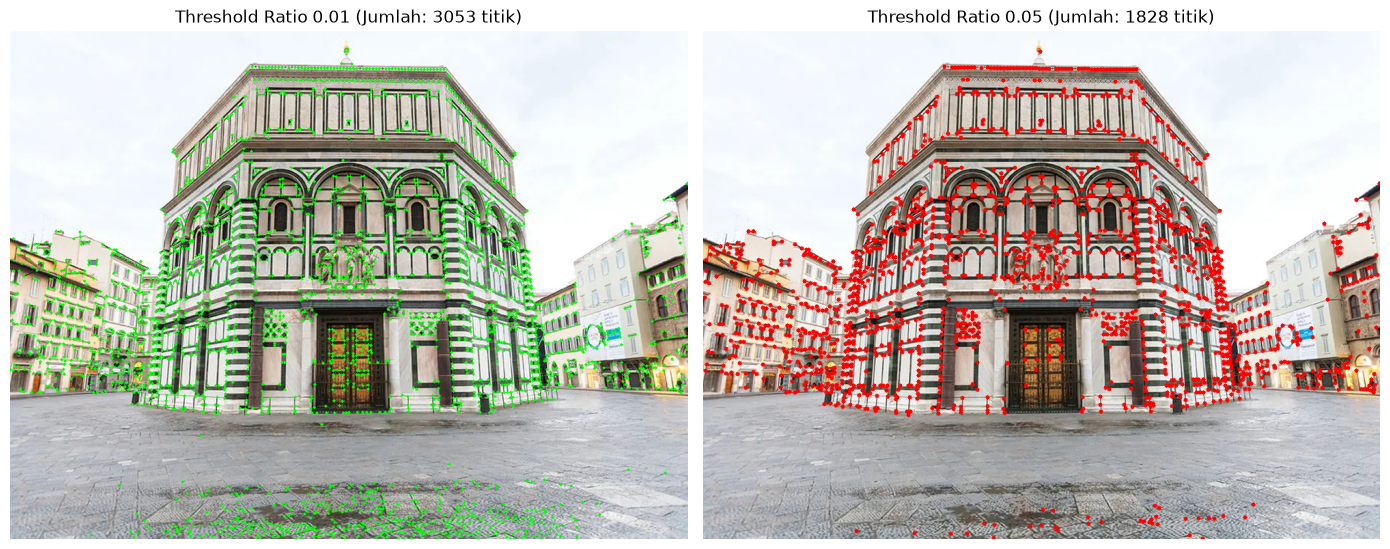

In [ ]:
corners_001, _ = extract_harris_corners(response, threshold_ratio=0.01, nms_size=5)
corners_005, _ = extract_harris_corners(response, threshold_ratio=0.05, nms_size=5)

img_t001 = draw_corners(img_bgr, corners_001, radius=2, color=(0, 255, 0))
img_t005 = draw_corners(img_bgr, corners_005, radius=3, color=(0, 0, 255))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.set_title(f"Threshold Ratio 0.01 (Jumlah: {len(corners_001)} titik)")
ax1.imshow(cv2.cvtColor(img_t001, cv2.COLOR_BGR2RGB))
ax1.axis("off")

ax2.set_title(f"Threshold Ratio 0.05 (Jumlah: {len(corners_005)} titik)")
ax2.imshow(cv2.cvtColor(img_t005, cv2.COLOR_BGR2RGB))
ax2.axis("off")

plt.tight_layout()
plt.show()


### Eksperimen 2: Pengaruh Windowing (Gaussian vs Box Filter)
* **Gaussian Window**: Memberikan bobot lebih besar pada piksel di pusat window, menghasilkan respon sudut yang lebih mulus dan stabil terhadap derau spasial.
* **Box Filter**: Memberikan bobot seragam pada seluruh piksel dalam window tanpa isotropi sirkular.


Sudut terdeteksi (Gaussian Window) : 1828
Sudut terdeteksi (Box Filter)     : 1453


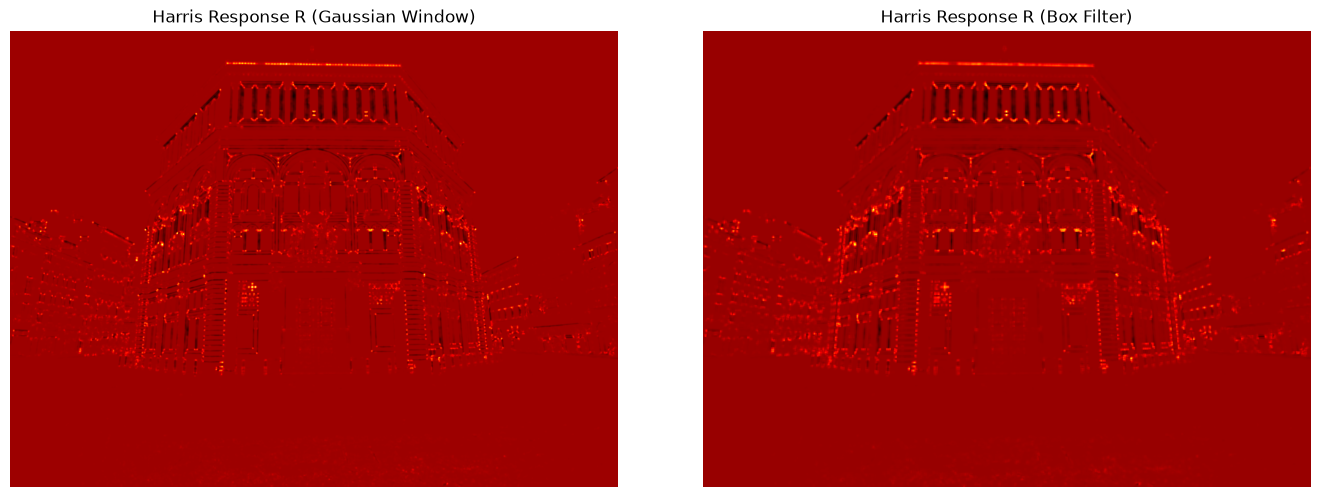

In [ ]:
resp_gauss, _, _, _ = harris_detector(img_gray, use_gaussian=True, sigma=1.0)
resp_box, _, _, _ = harris_detector(img_gray, use_gaussian=False)

c_gauss, _ = extract_harris_corners(resp_gauss, threshold_ratio=0.05, nms_size=5)
c_box, _ = extract_harris_corners(resp_box, threshold_ratio=0.05, nms_size=5)

print(f"Sudut terdeteksi (Gaussian Window) : {len(c_gauss)}")
print(f"Sudut terdeteksi (Box Filter)     : {len(c_box)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.set_title("Harris Response R (Gaussian Window)")
ax1.imshow(resp_gauss, cmap="hot")
ax1.axis("off")

ax2.set_title("Harris Response R (Box Filter)")
ax2.imshow(resp_box, cmap="hot")
ax2.axis("off")

plt.tight_layout()
plt.show()


---
## 6. Kesimpulan Praktikum

1. **Korelasi SSD dan Harris**: SSD ($E(u, v)$) mengukur pergeseran secara diskrit pada offset tertentu ($(u, v) = (5, 5)$), sedangkan Harris Corner Detector memodelkan semua arah pergeseran secara analitik melalui matriks struktur orde dua $M$.
2. **Kelebihan Operator Sobel & Formulasi Determinan-Trace**: Formulasi $R = \det(M) - k(\text{trace}(M))^2$ sangat efisien karena tidak memerlukan perhitungan *eigenvalue* eksplisit pada setiap piksel citra.
3. **Pentingnya NMS & Penyetelan Threshold**:
   * Dilation NMS berhasil mereduksi titik berkerumun menjadi satu titik puncak koordinat yang presisi.
   * Nilai `threshold_ratio = 0.05` terbukti efektif memisahkan sudut fitur arsitektural utama bangunan dari tekstur berulang pada lantai atau paving.
